
====================== XGBoost ======================
Confusion Matrix:
 [[244   5]
 [  9 425]]

Classification Report:
               precision    recall  f1-score   support

           0       0.96      0.98      0.97       249
           1       0.99      0.98      0.98       434

    accuracy                           0.98       683
   macro avg       0.98      0.98      0.98       683
weighted avg       0.98      0.98      0.98       683

AUC Score: 0.9988432994651416


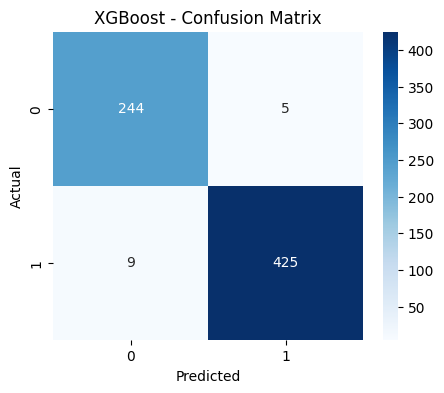

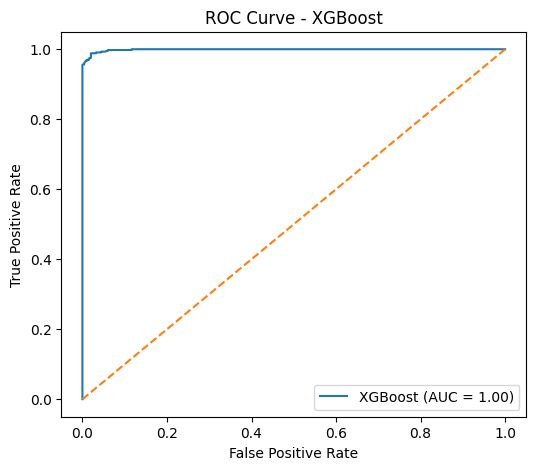


====================== Random Forest ======================
Confusion Matrix:
 [[246   3]
 [  8 426]]

Classification Report:
               precision    recall  f1-score   support

           0       0.97      0.99      0.98       249
           1       0.99      0.98      0.99       434

    accuracy                           0.98       683
   macro avg       0.98      0.98      0.98       683
weighted avg       0.98      0.98      0.98       683

AUC Score: 0.9989635963207669


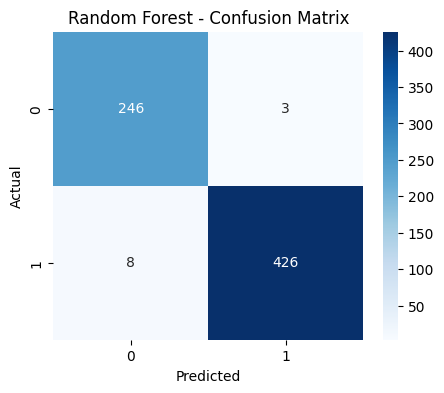

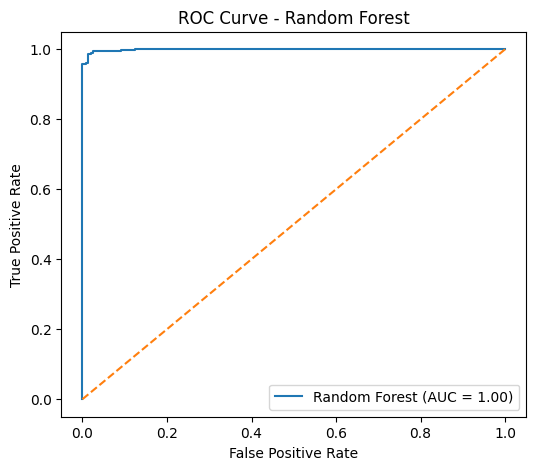


====================== Logistic Regression ======================
Confusion Matrix:
 [[169  80]
 [ 15 419]]

Classification Report:
               precision    recall  f1-score   support

           0       0.92      0.68      0.78       249
           1       0.84      0.97      0.90       434

    accuracy                           0.86       683
   macro avg       0.88      0.82      0.84       683
weighted avg       0.87      0.86      0.86       683

AUC Score: 0.9460329798456499


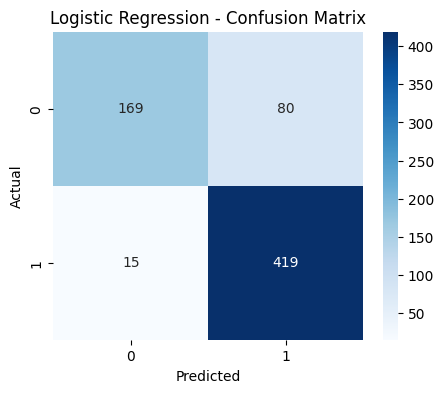

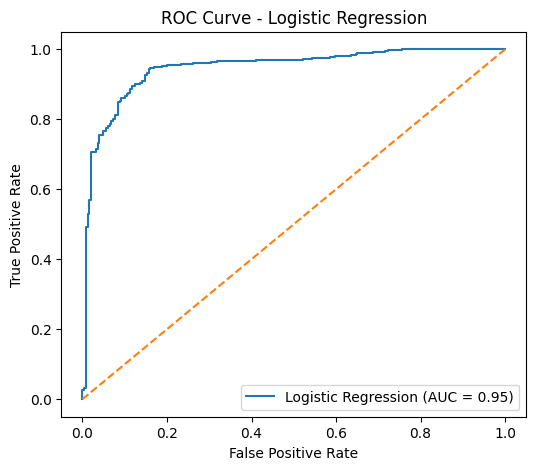


====================== SVM ======================
Confusion Matrix:
 [[166  83]
 [ 13 421]]

Classification Report:
               precision    recall  f1-score   support

           0       0.93      0.67      0.78       249
           1       0.84      0.97      0.90       434

    accuracy                           0.86       683
   macro avg       0.88      0.82      0.84       683
weighted avg       0.87      0.86      0.85       683

AUC Score: 0.9702404086391649


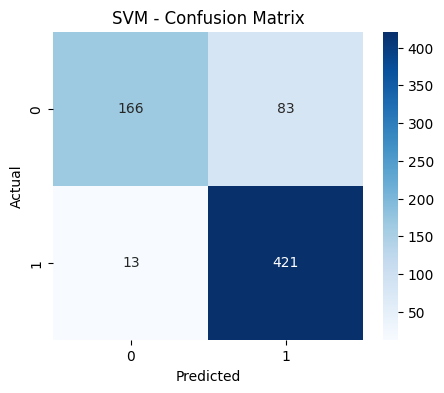

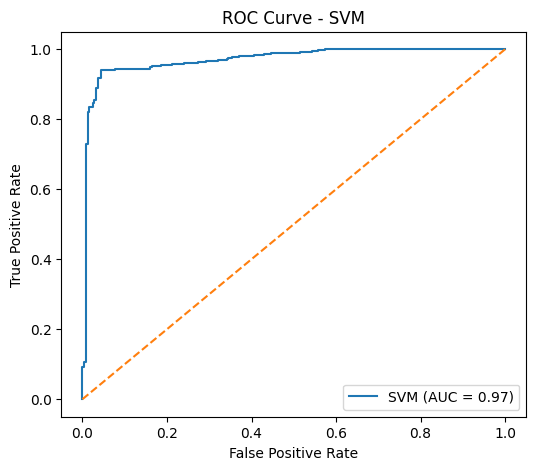


====================== KNN ======================
Confusion Matrix:
 [[249   0]
 [  9 425]]

Classification Report:
               precision    recall  f1-score   support

           0       0.97      1.00      0.98       249
           1       1.00      0.98      0.99       434

    accuracy                           0.99       683
   macro avg       0.98      0.99      0.99       683
weighted avg       0.99      0.99      0.99       683

AUC Score: 0.998301963614828


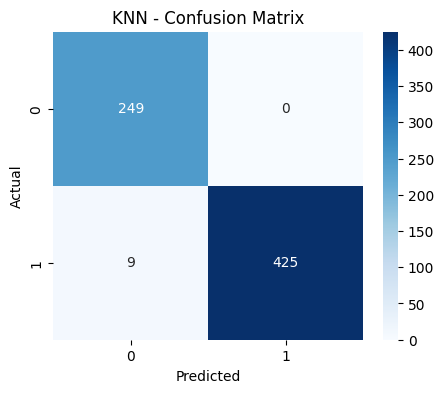

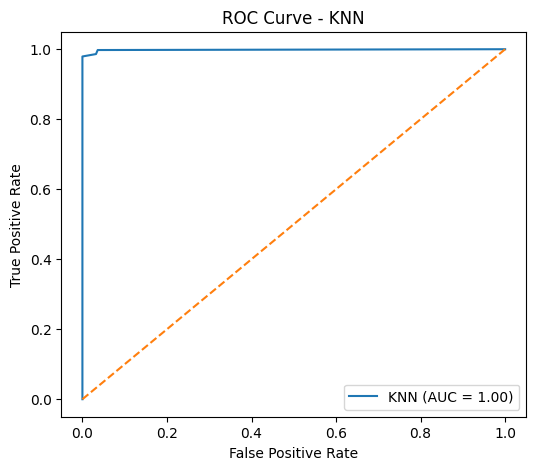



====== Final Model Comparison Table ======

                 Model  Accuracy  Precision    Recall  F1 Score       AUC
0              XGBoost  0.979502   0.988372  0.979263  0.983796  0.998843
1        Random Forest  0.983895   0.993007  0.981567  0.987254  0.998964
2  Logistic Regression  0.860908   0.839679  0.965438  0.898178  0.946033
3                  SVM  0.859444   0.835317  0.970046  0.897655  0.970240
4                  KNN  0.986823   1.000000  0.979263  0.989523  0.998302

Best model based on accuracy: KNN
Best model saved successfully!


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, roc_auc_score, roc_curve
)

from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
import xgboost as xgb

# Load dataset
df = pd.read_csv(r'F:\1. RESEARCH\Ashiq Sir\class - Copy\dataset_path\dataset_pathdataset.csv')

# Features and target
X = df.drop(['label', 'image_name'], axis=1)
y = df['label'].map({'Suspicious': 0, 'Normal': 1})

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# MODELS
models = {
    "XGBoost": xgb.XGBClassifier(
        n_estimators=50,
        eval_metric='logloss',
        objective='binary:logistic',
        tree_method='hist',
        eta=0.1,
        max_depth=3
    ),

    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42),

    "Logistic Regression": LogisticRegression(max_iter=200),

    "SVM": SVC(kernel="linear", probability=True),

    "KNN": KNeighborsClassifier(n_neighbors=5)
}

results = []
best_model = None
best_accuracy = 0

# Loop through models
for model_name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]  # For ROC

    # Metrics
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    auc = roc_auc_score(y_test, y_prob)
    cm = confusion_matrix(y_test, y_pred)

    results.append([model_name, acc, prec, rec, f1, auc])

    # Print classification results
    print(f"\n====================== {model_name} ======================")
    print("Confusion Matrix:\n", cm)
    print("\nClassification Report:\n", classification_report(y_test, y_pred))
    print(f"AUC Score: {auc}")

    # Plot Confusion Matrix Heatmap
    plt.figure(figsize=(5,4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
    plt.title(f"{model_name} - Confusion Matrix")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()

    # ROC Curve
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    plt.figure(figsize=(6,5))
    plt.plot(fpr, tpr, label=f"{model_name} (AUC = {auc:.2f})")
    plt.plot([0,1], [0,1], linestyle='--')
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title(f"ROC Curve - {model_name}")
    plt.legend()
    plt.show()

    # Track best model
    if acc > best_accuracy:
        best_accuracy = acc
        best_model = model_name

# Comparison Table
results_df = pd.DataFrame(results, columns=["Model", "Accuracy", "Precision", "Recall", "F1 Score", "AUC"])
print("\n\n====== Final Model Comparison Table ======\n")
print(results_df)

# Save the best model automatically
print(f"\nBest model based on accuracy: {best_model}")

if best_model == "XGBoost":
    models["XGBoost"].save_model(r"F:\1. RESEARCH\Ashiq Sir\class - Copy\\best_model.json")
else:
    import joblib
    joblib.dump(models[best_model], r"F:\1. RESEARCH\Ashiq Sir\class - Copy\best_model.pkl")

print("Best model saved successfully!")
